Validando endpoints oficiais...
1. Endpoint IBGE Regiões (N2): Status 200 | Registros: 10
2. Endpoint IBGE Estados (N3): Status 200 | Registros: 54
3. Endpoint BCB Olinda Juros : Status 200 | Registros: 500

Taxa Média Mensal de Referência (BCB): 0.89% a.m.

--- RESULTADO POR GRANDE REGIÃO (US07) ---


D2C,regiao,trimestre,taxa_desocupacao,taxa_subutilizacao,indice_possivel_inadimplencia,score_vulnerabilidade,produto_recomendado
1,Nordeste,3º trimestre 2026,6.6,20.6,13.29,100.00,Microcrédito Orientado (Alta Vulnerabilidade)
0,Norte,3º trimestre 2026,5.6,15.8,10.55,79.19,Microcrédito Orientado (Alta Vulnerabilidade)
2,Sudeste,3º trimestre 2026,5.2,11.1,8.24,61.50,Crédito Alternativo
4,Centro-Oeste,3º trimestre 2026,3.9,8.2,6.12,45.70,Crédito Alternativo
3,Sul,3º trimestre 2026,3.2,7.7,5.45,40.77,Crédito Tradicional



--- TOP 10 ESTADOS COM MAIOR VULNERABILIDADE (US07) ---


D2C,uf,taxa_desocupacao,taxa_subutilizacao,indice_possivel_inadimplencia,score_vulnerabilidade,produto_recomendado
8,Piauí,6.8,24.4,15.08,91.63,Microcrédito Orientado (Alta Vulnerabilidade)
15,Bahia,7.1,23.6,14.93,90.46,Microcrédito Orientado (Alta Vulnerabilidade)
12,Pernambuco,8.6,21.2,14.86,89.07,Microcrédito Orientado (Alta Vulnerabilidade)
13,Alagoas,6.8,22.5,14.25,86.35,Microcrédito Orientado (Alta Vulnerabilidade)
14,Sergipe,7.4,21.6,14.25,85.96,Microcrédito Orientado (Alta Vulnerabilidade)
7,Maranhão,6.0,21.7,13.38,81.32,Microcrédito Orientado (Alta Vulnerabilidade)
4,Pará,5.7,19.6,12.27,74.44,Microcrédito Orientado (Alta Vulnerabilidade)
1,Acre,6.3,17.8,11.87,71.55,Microcrédito Orientado (Alta Vulnerabilidade)
9,Ceará,5.7,16.3,10.83,65.28,Microcrédito Orientado (Alta Vulnerabilidade)
5,Amapá,7.9,12.1,10.44,61.35,Crédito Alternativo


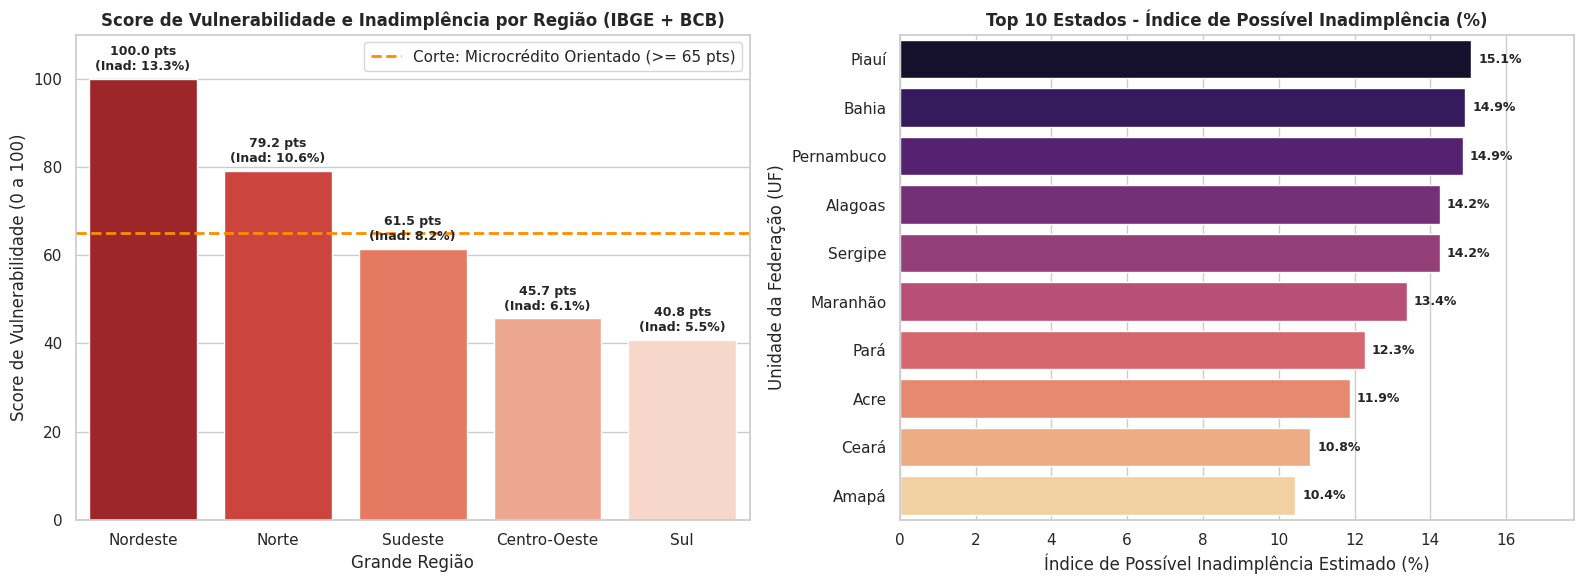


[Sucesso] Gráficos salvos em 'graficos_us07_validados.png' e JSONs exportados!


In [1]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. VALIDAÇÃO E CONSUMO DOS 3 ENDPOINTS OFICIAIS (IBGE SIDRA + BCB OLINDA)
# ==============================================================================
headers = {"User-Agent": "Mozilla/5.0"}

url_ibge_regioes = "https://apisidra.ibge.gov.br/values/t/4099/n2/all/v/4099,4118/p/last%201"
url_ibge_estados = "https://apisidra.ibge.gov.br/values/t/4099/n3/all/v/4099,4118/p/last%201"
url_bcb_juros = "https://olinda.bcb.gov.br/olinda/servico/taxaJuros/versao/v2/odata/TaxasJurosMensalPorMes?OData-MaxVersion=4.0&$top=500&$format=json"

print("Validando endpoints oficiais...")

res_reg = requests.get(url_ibge_regioes, headers=headers, timeout=15)
res_uf = requests.get(url_ibge_estados, headers=headers, timeout=15)
res_bcb = requests.get(url_bcb_juros, headers=headers, timeout=15)

print(f"1. Endpoint IBGE Regiões (N2): Status {res_reg.status_code} | Registros: {len(res_reg.json()) - 1}")
print(f"2. Endpoint IBGE Estados (N3): Status {res_uf.status_code} | Registros: {len(res_uf.json()) - 1}")
print(f"3. Endpoint BCB Olinda Juros : Status {res_bcb.status_code} | Registros: {len(res_bcb.json()['value'])}")

# ==============================================================================
# 2. ESTRUTURAÇÃO DOS DADOS DE REGIÕES, ESTADOS E JUROS DO BCB
# ==============================================================================
# Processando Taxa Média de Juros Mensal do BCB (Coluna real: 'TaxaJurosAoMes')
df_bcb = pd.DataFrame(res_bcb.json()["value"])
col_juros_bcb = "TaxaJurosAoMes" if "TaxaJurosAoMes" in df_bcb.columns else df_bcb.columns[4]
df_bcb["juros_mensal"] = pd.to_numeric(df_bcb[col_juros_bcb], errors="coerce")
juros_medio_bcb = df_bcb["juros_mensal"].dropna().mean()
print(f"\nTaxa Média Mensal de Referência (BCB): {juros_medio_bcb:.2f}% a.m.")

# Função para organizar o retorno da Tabela 4099 do SIDRA/IBGE
def processar_sidra_4099(json_data, tipo_local):
    # O índice [0] no SIDRA é o cabeçalho descritivo; os dados começam em [1:]
    df_raw = pd.DataFrame(json_data[1:])
    df_raw["V"] = pd.to_numeric(df_raw["V"], errors="coerce")

    # Pivotando as variáveis 4099 (Desocupação) e 4118 (Subutilização)
    df_pivot = df_raw.pivot(
        index=["D1C", "D1N", "D3N"],
        columns="D2C",
        values="V"
    ).reset_index().rename(columns={
        "D1C": "cod_ibge",
        "D1N": tipo_local,
        "D3N": "trimestre",
        "4099": "taxa_desocupacao",
        "4118": "taxa_subutilizacao"
    })

    # Hiato de Subutilização / Pressão de Informalidade (%)
    df_pivot["pressao_informalidade"] = (df_pivot["taxa_subutilizacao"] - df_pivot["taxa_desocupacao"]).round(2)
    return df_pivot

df_regioes = processar_sidra_4099(res_reg.json(), "regiao")
df_estados = processar_sidra_4099(res_uf.json(), "uf")

# ==============================================================================
# 3. METODOLOGIA DE CÁLCULO DO SCORE E ÍNDICE DE POSSÍVEL INADIMPLÊNCIA (US07)
# ==============================================================================
# Pesos da Metodologia:
# - 40% Taxa de Desocupação (Variável 4099 IBGE)
# - 40% Taxa Composta de Subutilização da Força de Trabalho (Variável 4118 IBGE)
# - 20% Pressão de Subocupação/Informalidade (Subutilização - Desocupação)
# O Índice de Possível Inadimplência (%) pondera a vulnerabilidade regional pelo custo médio do crédito (BCB).

def aplicar_metodologia_us07(df):
    fator_desoc = df["taxa_desocupacao"] / df["taxa_desocupacao"].max()
    fator_subut = df["taxa_subutilizacao"] / df["taxa_subutilizacao"].max()
    fator_infor = df["pressao_informalidade"] / df["pressao_informalidade"].max()

    # Score de Vulnerabilidade (Escala de 0 a 100)
    df["score_vulnerabilidade"] = (
        (fator_desoc * 0.40) +
        (fator_subut * 0.40) +
        (fator_infor * 0.20)
    ) * 100
    df["score_vulnerabilidade"] = df["score_vulnerabilidade"].round(2)

    # Índice de Possível Inadimplência Regional (%) combinado com a taxa média do BCB
    df["indice_possivel_inadimplencia"] = (
        ((df["taxa_desocupacao"] * 0.60) + (df["taxa_subutilizacao"] * 0.40)) * (1 + (juros_medio_bcb / 10))
    ).round(2)

    # Direcionamento de Produto de Crédito (US07)
    def recomendar_produto(score):
        if score >= 65:
            return "Microcrédito Orientado (Alta Vulnerabilidade)"
        elif score >= 45:
            return "Crédito Alternativo"
        else:
            return "Crédito Tradicional"

    df["produto_recomendado"] = df["score_vulnerabilidade"].apply(recomendar_produto)
    return df.sort_values(by="score_vulnerabilidade", ascending=False)

df_regioes = aplicar_metodologia_us07(df_regioes)
df_estados = aplicar_metodologia_us07(df_estados)

print("\n--- RESULTADO POR GRANDE REGIÃO (US07) ---")
display(df_regioes[["regiao", "trimestre", "taxa_desocupacao", "taxa_subutilizacao", "indice_possivel_inadimplencia", "score_vulnerabilidade", "produto_recomendado"]])

print("\n--- TOP 10 ESTADOS COM MAIOR VULNERABILIDADE (US07) ---")
display(df_estados[["uf", "taxa_desocupacao", "taxa_subutilizacao", "indice_possivel_inadimplencia", "score_vulnerabilidade", "produto_recomendado"]].head(10))

# ==============================================================================
# 4. GERAÇÃO DOS GRÁFICOS POR REGIÃO E ESTADO (PARA O SITE HTML / FLASK)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Score de Vulnerabilidade e Índice de Inadimplência por Região
ax1 = sns.barplot(
    ax=axes[0],
    data=df_regioes,
    x="regiao",
    y="score_vulnerabilidade",
    hue="regiao",
    palette="Reds_r",
    legend=False
)
axes[0].axhline(65, color="darkorange", linestyle="--", linewidth=2, label="Corte: Microcrédito Orientado (>= 65 pts)")
axes[0].set_title("Score de Vulnerabilidade e Inadimplência por Região (IBGE + BCB)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Grande Região")
axes[0].set_ylabel("Score de Vulnerabilidade (0 a 100)")
axes[0].set_ylim(0, 110)
axes[0].legend(loc="upper right")

for i, p in enumerate(ax1.patches):
    reg_row = df_regioes.iloc[i]
    texto = f"{reg_row['score_vulnerabilidade']:.1f} pts\n(Inad: {reg_row['indice_possivel_inadimplencia']:.1f}%)"
    ax1.annotate(
        texto,
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontsize=9, fontweight="bold", xytext=(0, 4), textcoords="offset points"
    )

# Gráfico 2: Top 10 Estados (UFs) por Índice de Possível Inadimplência (%)
top10_uf = df_estados.head(10)
ax2 = sns.barplot(
    ax=axes[1],
    data=top10_uf,
    x="indice_possivel_inadimplencia",
    y="uf",
    hue="uf",
    palette="magma",
    legend=False
)
axes[1].set_title("Top 10 Estados - Índice de Possível Inadimplência (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Índice de Possível Inadimplência Estimado (%)")
axes[1].set_ylabel("Unidade da Federação (UF)")
axes[1].set_xlim(0, top10_uf["indice_possivel_inadimplencia"].max() * 1.18)

for p in ax2.patches:
    width = p.get_width()
    ax2.annotate(
        f"{width:.1f}%",
        (width, p.get_y() + p.get_height() / 2.),
        ha="left", va="center", fontsize=9, fontweight="bold", xytext=(5, 0), textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("graficos_us07_validados.png", dpi=300)
plt.show()

# ==============================================================================
# 5. EXPORTAÇÃO DOS ARQUIVOS JSON PARA O SEU SITE HTML / FLASK
# ==============================================================================
df_regioes.to_json("dados_regioes_us07.json", orient="records", force_ascii=False, indent=4)
df_estados.to_json("dados_estados_us07.json", orient="records", force_ascii=False, indent=4)
print("\n[Sucesso] Gráficos salvos em 'graficos_us07_validados.png' e JSONs exportados!")
